In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# --- Simulation Parameters ---
T = 30.0              # total time
dt = 1.0              # time step
N = int(T / dt)       # number of steps
time = np.linspace(0, T, N)

# --- Model Parameters ---
theta = 0.15 			# mean-reversion rate
mu = 130.0				# target portfolio value
sigma_x0 = 2.0			# initial state variance
sigma_w = 2.0			# process noise strength  
sigma_v = 2.0			# output (observation) noise
R = 15					# control cost
Q = 10					# state deviation cost

# --- Discretized coefficients ---
a = 1 - theta * dt    # Euler discretization of A
b = -dt
c = 1.0               # Observation model

# --- LQR Control Gain DRE ---
P = Q
for _ in range(1000):
    P = Q + a**2 * P - (a * b * P)**2 / (R + b**2 * P)
K = (a * b * P) / (R + b**2 * P)

# --- Kalman Filter Gain (Nominal) ---
Qw = sigma_w**2 * dt  # process noise variance
Rv = sigma_v**2 # measurement noise variance
Sigma = sigma_x0 	 # To compute the Kalman gain, we need to initialize Sigma which is the variance of the state estimate at inital state so x0
	             # We define a new variable to not crush the original sigma_x0 variable as the Sigma variable is used repeatedly in the loop.
for _ in range(1000):
    Sigma = a**2 * Sigma + Qw - (a * Sigma * c)**2 / (c**2 * Sigma + Rv)
L = a * Sigma * c / (c**2 * Sigma + Rv)

# --- Robustified Covariances (example values from SDP output) ---
Qw_rob = 1.5 * Qw       # robustified process noise variance
Rv_rob = 1.5 * Rv       # robustified measurement noise variance
Sigma_rob = 2.0         # robustified initial state variance

# --- Robust Kalman Gain ---
for _ in range(1000):
    Sigma_rob = a**2 * Sigma_rob + Qw_rob - (a * Sigma_rob * c)**2 / (c**2 * Sigma_rob + Rv_rob)
L_rob = a * Sigma_rob * c / (c**2 * Sigma_rob + Rv_rob)

# --- Initialization ---
x = np.zeros(N)         # True state (nominal)
z = np.zeros(N)         # Ture transformed state z_k = mu - x_k
u = np.zeros(N)
y = np.zeros(N)         # Noisy measurment of z
z_hat = np.zeros(N)     # Kalman filter estimate of z

x_rob = np.zeros(N)     # Robust simulation
z_rob = np.zeros(N)
u_rob = np.zeros(N)
z_hat_rob = np.zeros(N)

x[0] = 120.0
z[0] = mu - x[0]
z_hat[0] = z[0] + np.random.normal(0, sigma_v)

x_rob[0] = x[0]
z_rob[0] = mu - x_rob[0]
z_hat_rob[0] = z_rob[0] + np.random.normal(0, np.sqrt(Rv_rob))

# --- Simulation Loop ---
for k in range(1, N):
    # --- Nominal LQG ---
    u[k] = -K * z_hat[k-1]
    w_k = np.random.normal(0, sigma_w * np.sqrt(dt))
    z[k] = a * z[k-1] + b * u[k] + w_k
    x[k] = mu - z[k]
    v_k = np.random.normal(0, sigma_v)
    y[k] = c * z[k] + v_k
    z_hat[k] = a * z_hat[k-1] + b * u[k] + L * (y[k] - c * (a * z_hat[k-1] + b * u[k]))

    # --- Robustified LQG ---
    u_rob[k] = -K * z_hat_rob[k-1]
    w_kr = np.random.normal(0, np.sqrt(Qw_rob))
    z_rob[k] = a * z_rob[k-1] + b * u_rob[k] + w_kr
    x_rob[k] = mu - z_rob[k]
    v_kr = np.random.normal(0, np.sqrt(Rv_rob))
    y_kr = c * z_rob[k] + v_kr
    z_hat_rob[k] = a * z_hat_rob[k-1] + b * u_rob[k] + L_rob * (y_kr - c * (a * z_hat_rob[k-1] + b * u_rob[k]))



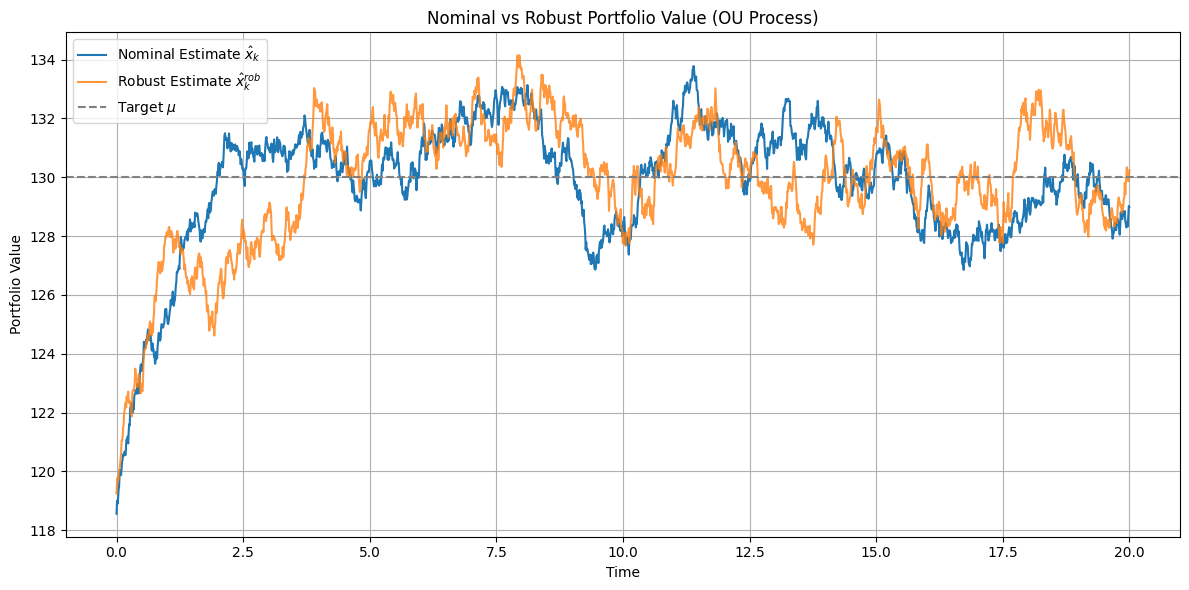

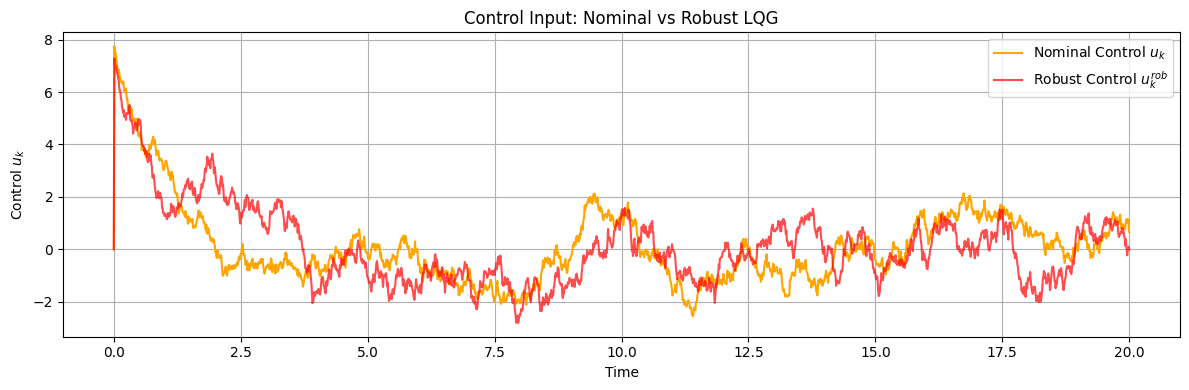

In [3]:
# --- Plot Portfolio Value ---
plt.figure(figsize=(12, 6))
#plt.plot(time, x, label='Nominal Portfolio Value $x_k$', linewidth=2)
plt.plot(time, mu - z_hat, label='Nominal Estimate $\hat{x}_k$')
#plt.plot(time, x_rob, label='Robust Portfolio Value $x_k^{rob}$', linewidth=2, alpha=0.8)
plt.plot(time, mu - z_hat_rob, label='Robust Estimate $\hat{x}_k^{rob}$', alpha=0.8)
plt.axhline(mu, color='gray', linestyle='--', label='Target $\\mu$')
plt.title("Nominal vs Robust Portfolio Value (OU Process)")
plt.xlabel("Time")
plt.ylabel("Portfolio Value")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# --- Plot Control Input ---
plt.figure(figsize=(12, 4))
plt.plot(time, u, label='Nominal Control $u_k$', color='orange')
plt.plot(time, u_rob, label='Robust Control $u_k^{rob}$', color='red', alpha=0.7)
plt.title("Control Input: Nominal vs Robust LQG")
plt.xlabel("Time")
plt.ylabel("Control $u_k$")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
